In [5]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [3]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (Parte 6)

from flows.common.paths import BRONZE, SILVER, GOLD, BRONZE_LABELED_NAME, SILVER_NAME

# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

# 3) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

In [5]:
df.head(10)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [10]:
#Paso 1
df.shape

(891, 12)

In [13]:
#Paso 2
df.columns

# Consultar los tipos de datos de cada columna
df.dtypes


PassengerId      int64
Survived       float64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [14]:

df.info()



<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(3), int64(4), str(5)
memory usage: 118.9 KB


In [15]:
#Paso 3
# Mostrar los primeros 10 pasajeros
df.head(10)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [17]:
#Paso 4

# Estadísticas descriptivas de las variables numéricas
df.describe()


# Estadísticas descriptivas de las columnas no numéricas
df.select_dtypes(exclude='number').describe()



,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [18]:
#Paso 5 

# Contar los valores nulos por columna
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [19]:
#5.2
# Calcular el porcentaje de valores nulos
(df.isnull().sum() / len(df)) * 100


PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [20]:
#5.3

# Resumen de valores faltantes
faltantes = pd.DataFrame({
    'Valores faltantes': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df)) * 100
})

faltantes.sort_values(
    by='Valores faltantes',
    ascending=False
)


,Valores faltantes,Porcentaje (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
SibSp,0,0.000000
Parch,0,0.000000


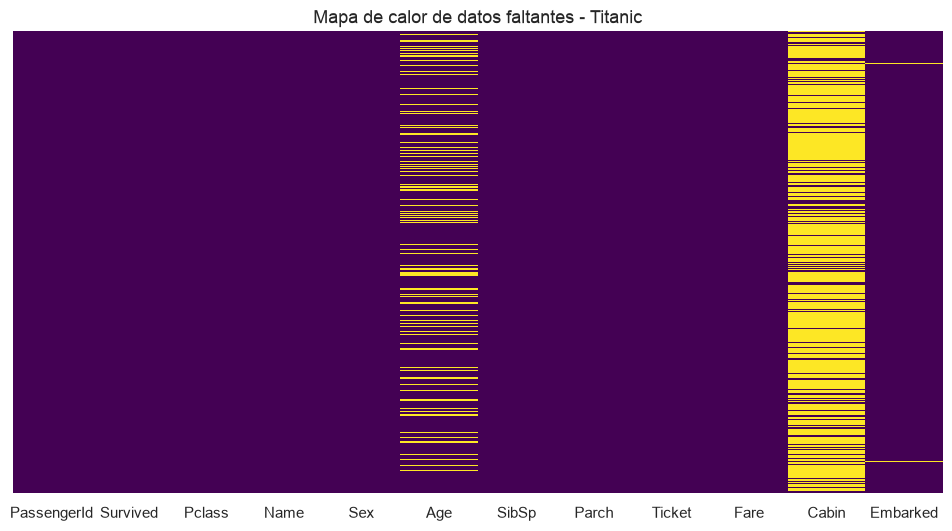

In [21]:
#5.4
# Crear el mapa de calor de los valores faltantes
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Mapa de calor de datos faltantes - Titanic')
plt.show()


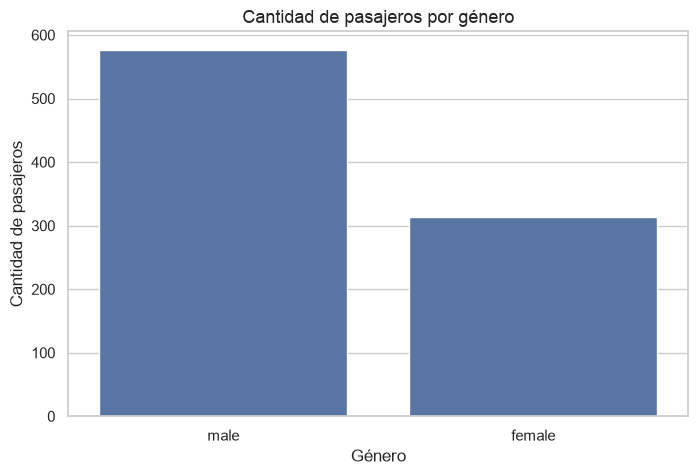

In [22]:
#6.1

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Sex')

plt.title('Cantidad de pasajeros por género')
plt.xlabel('Género')
plt.ylabel('Cantidad de pasajeros')

plt.show()


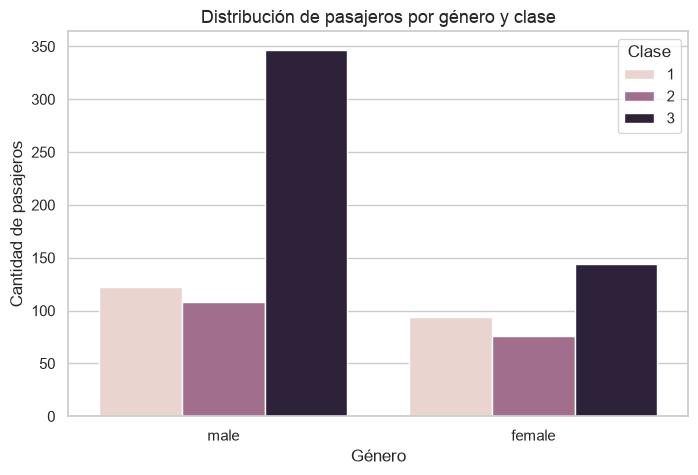

In [23]:
#5.2

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Sex', hue='Pclass')

plt.title('Distribución de pasajeros por género y clase')
plt.xlabel('Género')
plt.ylabel('Cantidad de pasajeros')
plt.legend(title='Clase')

plt.show()


In [24]:
#6.3

tabla_genero_clase = pd.crosstab(
    df['Sex'],
    df['Pclass'],
    normalize='columns'
)

tabla_genero_clase


Pclass,1,2,3
Sex,,,
female,0.435185,0.413043,0.293279
male,0.564815,0.586957,0.706721


In [28]:
df['Age'].mean()

np.float64(29.69911764705882)

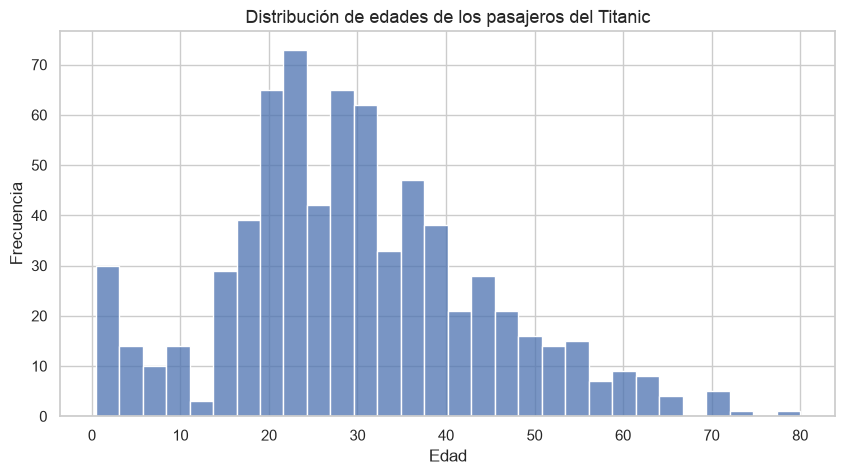

In [25]:
#7.1

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Age',
    bins=30
)

plt.title('Distribución de edades de los pasajeros del Titanic')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')

plt.show()


In [26]:
#7.2

edad_promedio = df['Age'].mean()

print(f"Edad promedio: {edad_promedio:.2f} años")


Edad promedio: 29.70 años


In [27]:

print(f"Mediana: {df['Age'].median():.2f} años")
print(f"Edad mínima: {df['Age'].min():.2f} años")
print(f"Edad máxima: {df['Age'].max():.2f} años")


Mediana: 28.00 años
Edad mínima: 0.42 años
Edad máxima: 80.00 años


In [29]:
#8.1
import importlib

ing = importlib.import_module("flows.01_data_engineering")

df_person = ing.add_person(df)

In [30]:
#8.2
df_person['Person'].value_counts()

Person
male      537
female    271
child      83
Name: count, dtype: int64

In [31]:
#8.3
df_person['Person'].value_counts(normalize=True) * 100

Person
male      60.269360
female    30.415264
child      9.315376
Name: proportion, dtype: float64

In [32]:
#8.4
# Pasajeros con edad conocida
edad_conocida = df['Age'].dropna()

# Proporción de niños entre quienes tienen edad conocida
proporcion_ninos = (edad_conocida < 16).mean()

# Pasajeros sin edad registrada
edades_faltantes = df['Age'].isna().sum()

# Estimación de niños no identificados
ninos_estimados = proporcion_ninos * edades_faltantes

print(f"Proporción de niños: {proporcion_ninos:.2%}")
print(f"Edades faltantes: {edades_faltantes}")
print(f"Niños posiblemente no identificados: {ninos_estimados:.0f}")

Proporción de niños: 11.62%
Edades faltantes: 177
Niños posiblemente no identificados: 21


In [35]:
#9.1
tabla_person_clase = pd.crosstab(
    df_person['Pclass'],
    df_person['Person']
)

tabla_person_clase

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


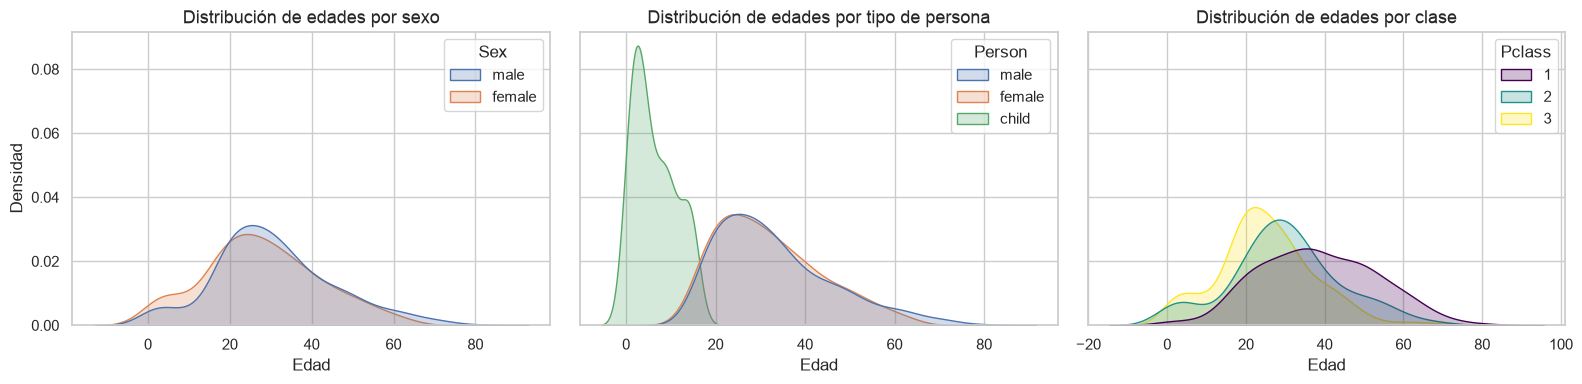

In [37]:
#10
# Comparación de la distribución de edades mediante gráficos KDE
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4),
    sharey=True
)

# 1. Distribución de edades por sexo
sns.kdeplot(
    data=df,
    x='Age',
    hue='Sex',
    fill=True,
    common_norm=False,
    ax=axes[0]
)

axes[0].set_title('Distribución de edades por sexo')

# 2. Distribución de edades por tipo de persona
sns.kdeplot(
    data=df_person,
    x='Age',
    hue='Person',
    fill=True,
    common_norm=False,
    ax=axes[1]
)

axes[1].set_title('Distribución de edades por tipo de persona')

# 3. Distribución de edades por clase
sns.kdeplot(
    data=df,
    x='Age',
    hue='Pclass',
    fill=True,
    common_norm=False,
    palette='viridis',
    ax=axes[2]
)

axes[2].set_title('Distribución de edades por clase')

# Ajustes generales
for ax in axes:
    ax.set_xlabel('Edad')
    ax.set_ylabel('Densidad')

plt.tight_layout()
plt.show()

In [39]:
#12
# Seleccionar únicamente pasajeros con cubierta conocida
cubierta = df.loc[df['Cabin'].notna(), 'Cabin'].str[0]

# Revisar la cantidad de pasajeros por cubierta
cubierta.value_counts().sort_index()

Cabin
A    15
B    47
C    59
D    33
E    32
F    13
G     4
T     1
Name: count, dtype: int64

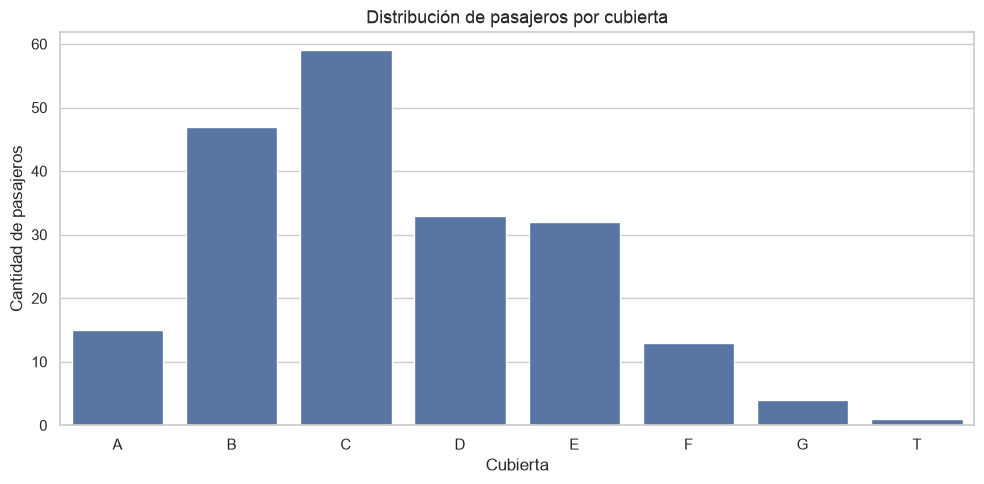

In [40]:
#12.1
# Gráfico de pasajeros por cubierta
plt.figure(figsize=(10, 5))

sns.countplot(
    x=cubierta,
    order=sorted(cubierta.unique())
)

plt.title('Distribución de pasajeros por cubierta')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad de pasajeros')

plt.tight_layout()
plt.show()

In [41]:
#12.2
# Revisar cubiertas con un solo registro
cubierta.value_counts()

Cabin
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64

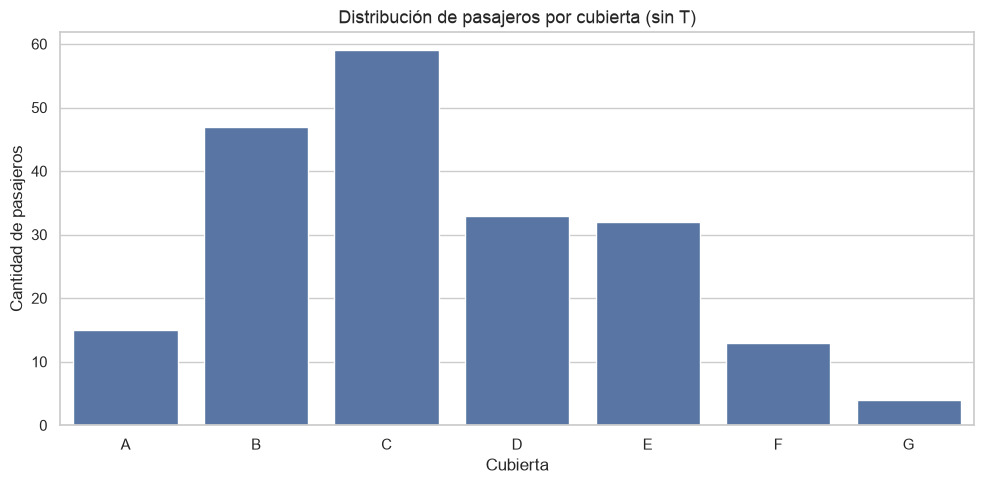

In [42]:
# Excluir cubierta T únicamente del gráfico
cubierta_sin_t = cubierta[cubierta != 'T']

plt.figure(figsize=(10, 5))

sns.countplot(
    x=cubierta_sin_t,
    order=sorted(cubierta_sin_t.unique())
)

plt.title('Distribución de pasajeros por cubierta (sin T)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad de pasajeros')

plt.tight_layout()
plt.show()

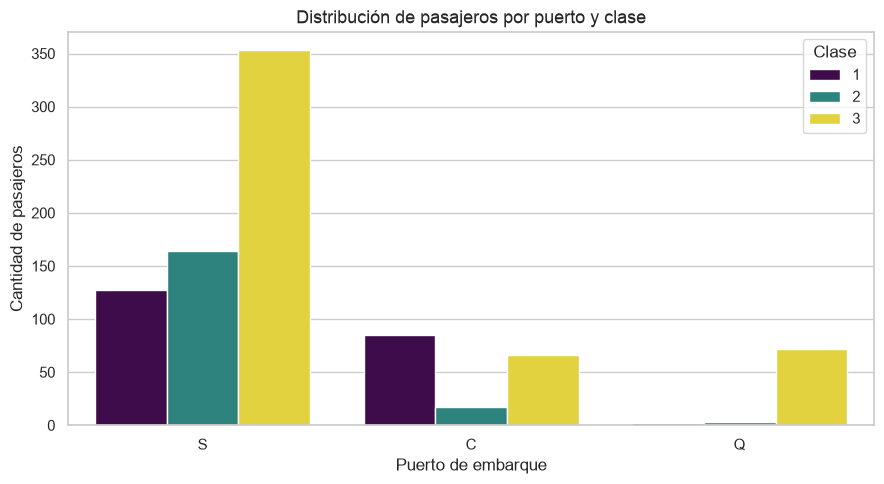

In [43]:
#13
# Distribución de pasajeros por puerto y clase
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Embarked',
    hue='Pclass',
    palette='viridis'
)

plt.title('Distribución de pasajeros por puerto y clase')
plt.xlabel('Puerto de embarque')
plt.ylabel('Cantidad de pasajeros')
plt.legend(title='Clase')

plt.tight_layout()
plt.show()

In [44]:
#13.1
# Tabla cruzada entre puerto de embarque y clase
tabla_embarked_pclass = pd.crosstab(
    df['Embarked'],
    df['Pclass'],
    normalize='index'
) * 100

display(tabla_embarked_pclass.round(2))

Pclass,1,2,3
Embarked,,,
C,50.60,10.12,39.29
Q,2.60,3.90,93.51
S,19.72,25.47,54.81


In [47]:
import importlib

ing = importlib.reload(ing)

In [50]:
df_familia["Alone"].value_counts()

Alone
Alone          537
with Family    354
Name: count, dtype: int64

In [51]:
df_familia["Familia"].value_counts().sort_index()

Familia
0     537
1     161
2     102
3      29
4      15
5      22
6      12
7       6
10      7
Name: count, dtype: int64

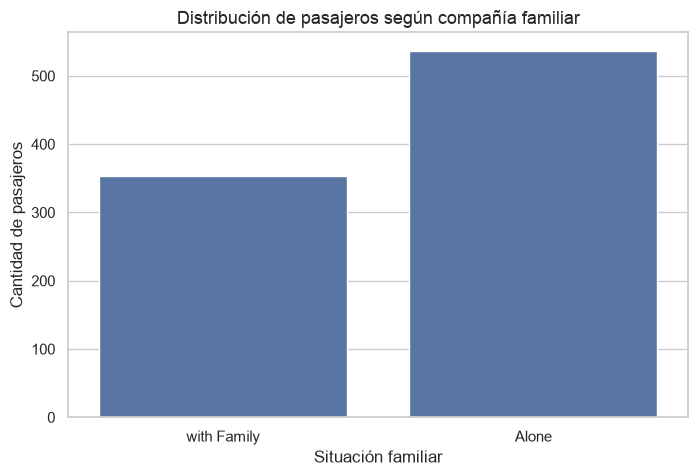

In [52]:
#15
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_familia,
    x="Alone"
)

plt.title("Distribución de pasajeros según compañía familiar")
plt.xlabel("Situación familiar")
plt.ylabel("Cantidad de pasajeros")

plt.show()

In [59]:
import importlib

ing = importlib.reload(ing)

In [61]:
df_survivor = ing.add_survivor_label(df_familia)

df_survivor["Survivor"].value_counts()

Survivor
No     549
Yes    342
Name: count, dtype: int64

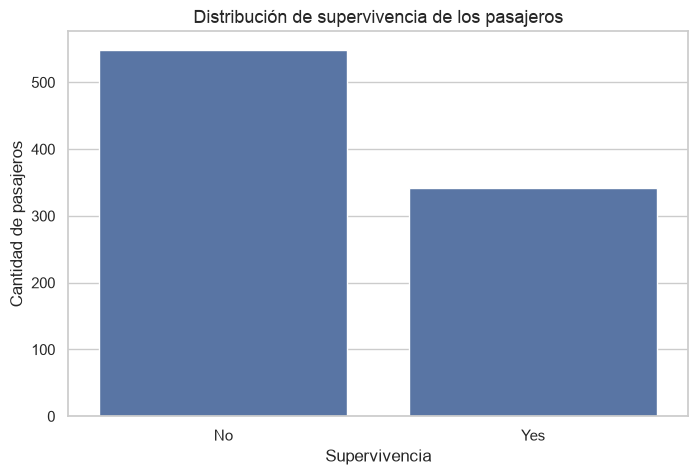

In [63]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_survivor, x="Survivor")

plt.title("Distribución de supervivencia de los pasajeros")
plt.xlabel("Supervivencia")
plt.ylabel("Cantidad de pasajeros")

plt.show()

In [64]:
tasa_supervivencia = df_survivor["Survived"].mean()

print(f"Tasa de supervivencia: {tasa_supervivencia:.2%}")

Tasa de supervivencia: 38.38%


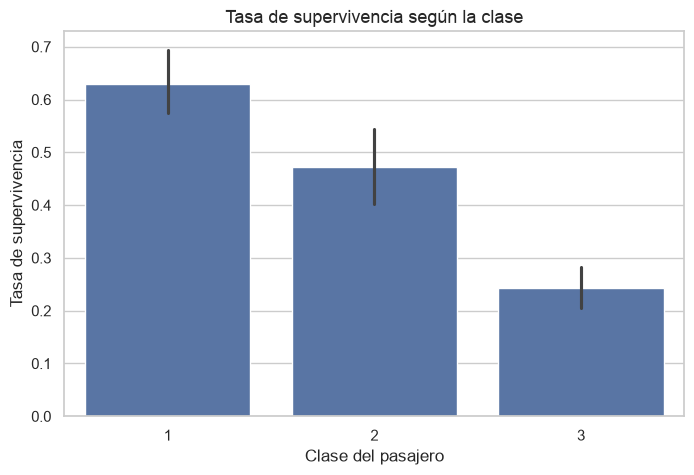

In [65]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_survivor,
    x="Pclass",
    y="Survived"
)

plt.title("Tasa de supervivencia según la clase")
plt.xlabel("Clase del pasajero")
plt.ylabel("Tasa de supervivencia")

plt.show()

In [66]:
df_survivor.groupby("Pclass")["Survived"].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

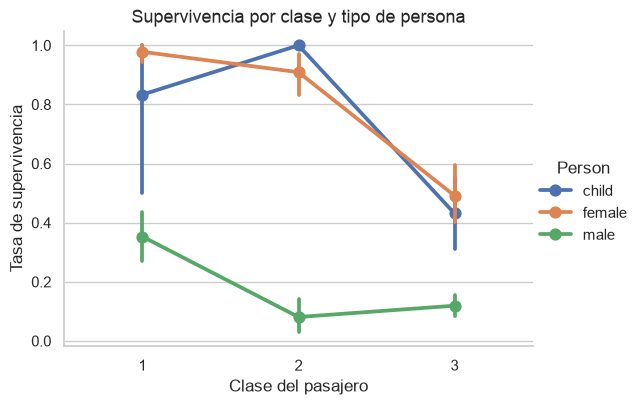

In [67]:
sns.catplot(
    data=df_survivor,
    x="Pclass",
    y="Survived",
    hue="Person",
    hue_order=["child", "female", "male"],
    kind="point",
    height=4,
    aspect=1.4
)

plt.title("Supervivencia por clase y tipo de persona")
plt.ylabel("Tasa de supervivencia")
plt.xlabel("Clase del pasajero")

plt.show()

In [68]:
tabla_supervivencia_persona = pd.crosstab(
    [df_survivor["Pclass"], df_survivor["Person"]],
    df_survivor["Survived"],
    normalize="index"
) * 100

tabla_supervivencia_persona

Survived             0.0         1.0
Pclass Person                       
1      child   16.666667   83.333333
       female   2.197802   97.802198
       male    64.705882   35.294118
2      child    0.000000  100.000000
       female   9.090909   90.909091
       male    91.919192    8.080808
3      child   56.896552   43.103448
       female  50.877193   49.122807
       male    88.087774   11.912226

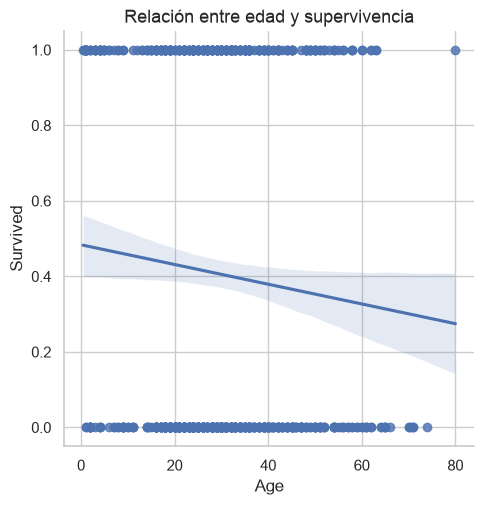

In [69]:
sns.lmplot(
    data=df_survivor,
    x="Age",
    y="Survived"
)

plt.title("Relación entre edad y supervivencia")
plt.show()

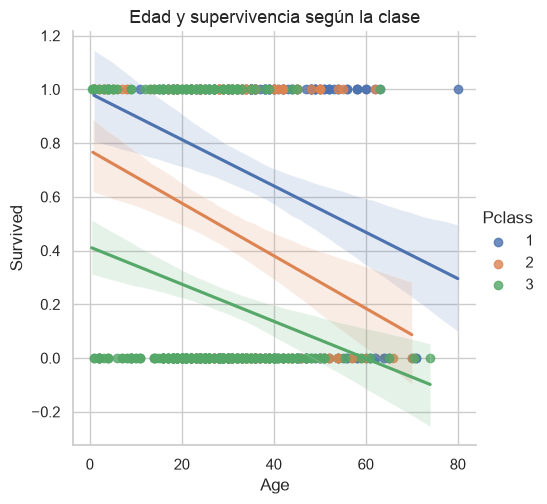

In [70]:
sns.lmplot(
    data=df_survivor,
    x="Age",
    y="Survived",
    hue="Pclass"
)

plt.title("Edad y supervivencia según la clase")
plt.show()

In [71]:
generaciones = [10, 20, 40, 60, 80]

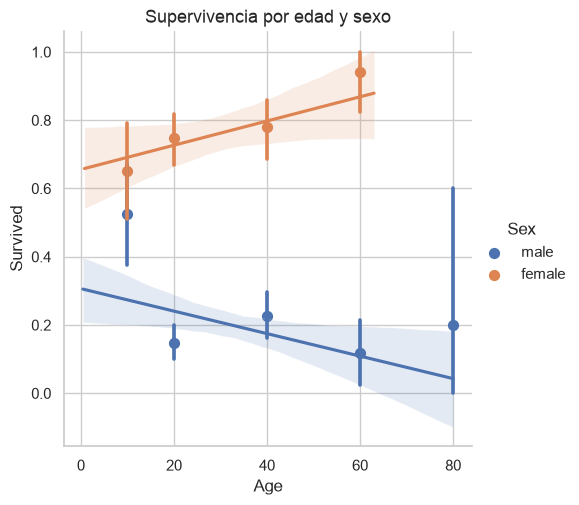

In [72]:
sns.lmplot(
    data=df_survivor,
    x="Age",
    y="Survived",
    x_bins=generaciones,
    hue="Sex"
)

plt.title("Supervivencia por edad y sexo")
plt.show()

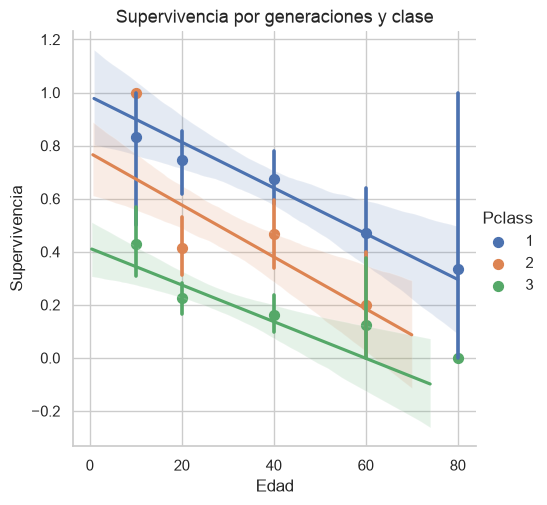

In [73]:
generaciones = [10, 20, 40, 60, 80]

sns.lmplot(
    data=df_survivor,
    x="Age",
    y="Survived",
    x_bins=generaciones,
    hue="Pclass"
)

plt.title("Supervivencia por generaciones y clase")
plt.xlabel("Edad")
plt.ylabel("Supervivencia")

plt.show()

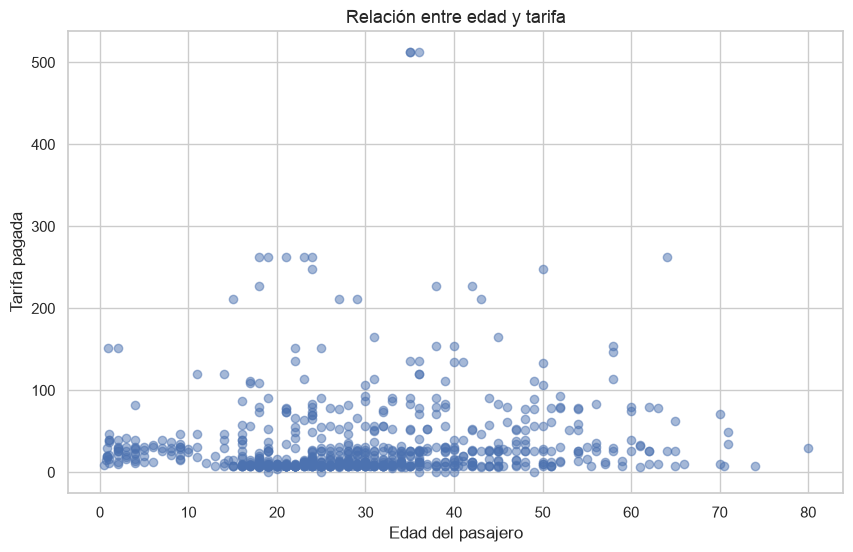

In [74]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_survivor["Age"],
    df_survivor["Fare"],
    alpha=0.5
)

plt.title("Relación entre edad y tarifa")
plt.xlabel("Edad del pasajero")
plt.ylabel("Tarifa pagada")

plt.show()

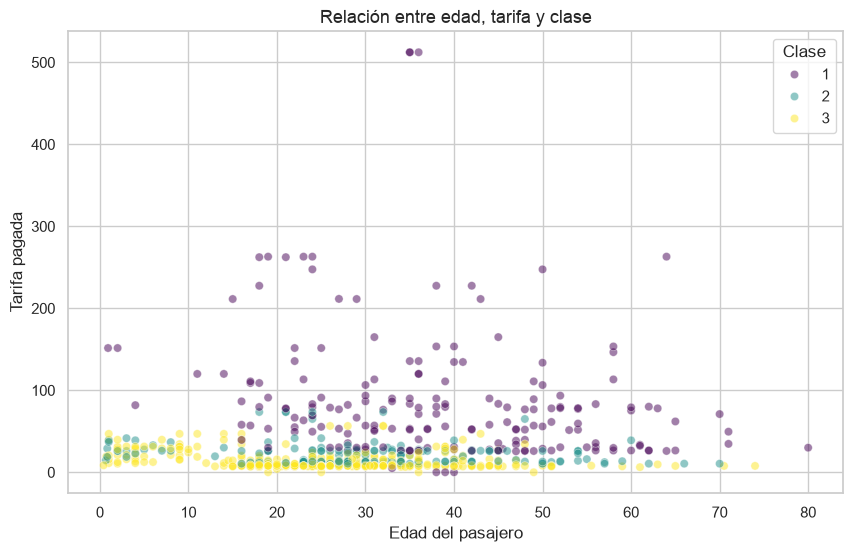

In [75]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_survivor,
    x="Age",
    y="Fare",
    hue="Pclass",
    alpha=0.5,
    palette="viridis"
)

plt.title("Relación entre edad, tarifa y clase")
plt.xlabel("Edad del pasajero")
plt.ylabel("Tarifa pagada")
plt.legend(title="Clase")

plt.show()

In [76]:
df_survivor["Embarked"].isnull().sum()

np.int64(2)

In [77]:
df_survivor["Embarked"].mode()[0]

'S'

In [78]:
df_survivor["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [101]:
import importlib

ing = importlib.reload(ing)

In [92]:
import importlib
ing = importlib.reload(ing)

df_embarked = ing.impute_embarked(df_survivor)

print(type(df_embarked))
print("Valores faltantes:", df_embarked["Embarked"].isnull().sum())

<class 'pandas.DataFrame'>
Valores faltantes: 0


In [91]:
df_encoded = ing.encode_categoricals(df_embarked)

df_encoded[["Embarked", "NEmbarked"]].value_counts().sort_index()

Embarked  NEmbarked
C         1.0          168
Q         2.0           77
S         0.0          644
Name: count, dtype: int64

In [94]:
df_age = ing.impute_age(df_encoded)

2026-11-06 22:11:57,070 | INFO | flows.01_data_engineering | Desviación estándar de Age antes de imputar: 14.53
2026-11-06 22:11:57,073 | INFO | flows.01_data_engineering | Desviación estándar de Age después de imputar: 13.01


In [95]:
print("Edades faltantes antes:", df_age["AgeOriginal"].isna().sum())
print("Edades faltantes después:", df_age["Age"].isna().sum())

print("Edades imputadas:", df_age["AgeImputada"].sum())

df_age[["Sex", "AgeOriginal", "Age", "AgeImputada"]].head(10)

Edades faltantes antes: 177
Edades faltantes después: 0
Edades imputadas: 177


,Sex,AgeOriginal,Age,AgeImputada
0,male,22.0,22.000000,False
1,female,38.0,38.000000,False
2,female,26.0,26.000000,False
3,female,35.0,35.000000,False
4,male,35.0,35.000000,False
5,male,NaN,30.726645,True
6,male,54.0,54.000000,False
7,male,2.0,2.000000,False
8,female,27.0,27.000000,False
9,female,14.0,14.000000,False


In [96]:
print("Desviación estándar original:",
      df_age["AgeOriginal"].std())

print("Desviación estándar imputada:",
      df_age["Age"].std())

Desviación estándar original: 14.526497332334042
Desviación estándar imputada: 13.014896879381995


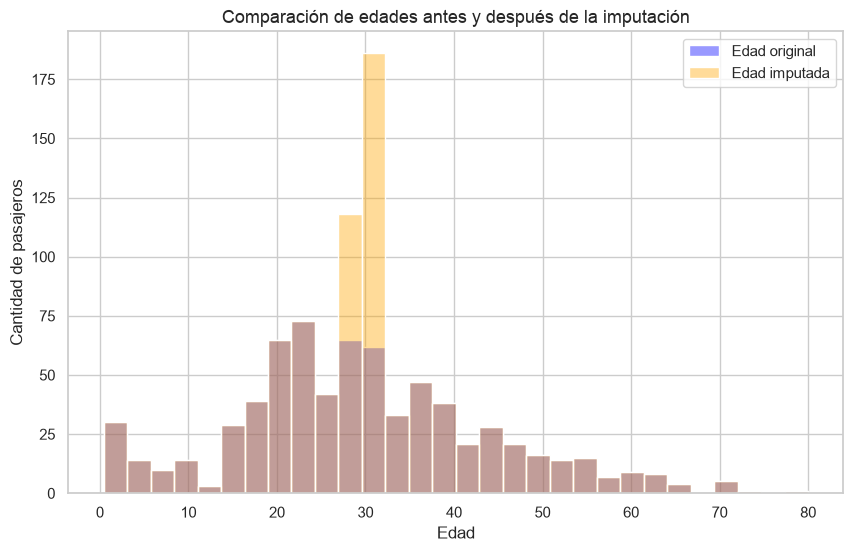

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    df_age["AgeOriginal"].dropna(),
    bins=30,
    color="blue",
    alpha=0.4,
    label="Edad original"
)

sns.histplot(
    df_age["Age"],
    bins=30,
    color="orange",
    alpha=0.4,
    label="Edad imputada"
)

plt.title("Comparación de edades antes y después de la imputación")
plt.xlabel("Edad")
plt.ylabel("Cantidad de pasajeros")
plt.legend()
plt.show()

In [99]:
df_encoded = ing.encode_categoricals(df_embarked)

df_encoded[["Sex", "NSex"]].value_counts().sort_index()

Sex     NSex
female  0       314
male    1       577
Name: count, dtype: int64

In [100]:
print("Nulos en Embarked:", df_encoded["Embarked"].isna().sum())
print("Nulos en NEmbarked:", df_encoded["NEmbarked"].isna().sum())

print(df_encoded["Embarked"].value_counts(dropna=False))

Nulos en Embarked: 0
Nulos en NEmbarked: 0
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


In [114]:
import importlib
ing = importlib.reload(ing)

In [108]:
df_encoded = ing.encode_categoricals(df_cabin)

df_encoded[["TCabin", "NCabin"]].value_counts().sort_index()

TCabin  NCabin
A       0          15
B       1          47
C       2          59
D       3          33
E       4          32
F       5          13
G       6           4
T       7           1
X       8         687
Name: count, dtype: int64

In [107]:
df_cabin = ing.add_cabin_features(df_embarked)

df_cabin[["Cabin", "TCabin"]].head()

,Cabin,TCabin
0,NaN,X
1,C85,C
2,NaN,X
3,C123,C
4,NaN,X


In [109]:
df_encoded[["NEmbarked", "NSex", "NCabin"]].isnull().sum()

NEmbarked    0
NSex         0
NCabin       0
dtype: int64

In [111]:
df_titulo = ing.add_title(df_encoded)

df_titulo[["Name", "TTitulo"]].head(10)

,Name,TTitulo
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr
5,"Moran, Mr. James",Mr
6,"McCarthy, Mr. Timothy J",Mr
7,"Palsson, Master. Gosta Leonard",Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [112]:
df_titulo["TTitulo"].value_counts()

TTitulo
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [113]:
pd.crosstab(df_titulo["TTitulo"], df_titulo["Sex"])

Sex,female,male
TTitulo,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


In [116]:
df_codificado = ing.encode_categoricals(df_consolidado)

df_codificado[["TTitulo", "NTitulo"]].drop_duplicates().sort_values("NTitulo")

,TTitulo,NTitulo
0,Mr,0
1,Mrs,1
2,Miss,2
30,Otro,3


In [117]:
df_codificado["TTitulo"].value_counts()

TTitulo
Mr      557
Miss    186
Mrs     127
Otro     21
Name: count, dtype: int64

In [118]:
cols = [
    "Survived", "Pclass", "NSex", "Age",
    "SibSp", "Parch", "Fare", "NEmbarked",
    "NCabin", "NTitulo"
]

In [119]:
corr = df_codificado[cols].corr()

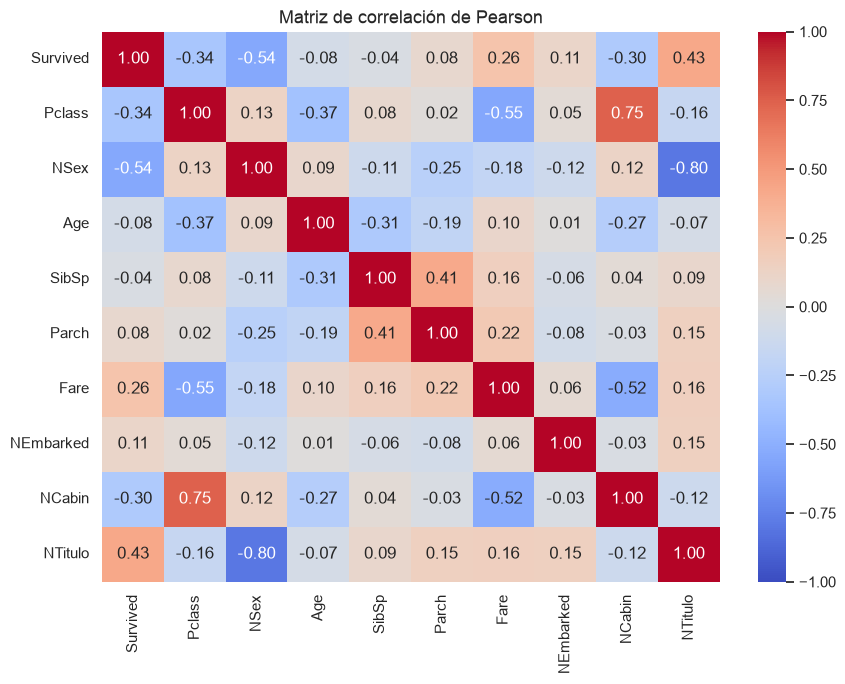

In [120]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

In [121]:
corr["Survived"].sort_values()

NSex        -0.543351
Pclass      -0.338481
NCabin      -0.301116
Age         -0.077221
SibSp       -0.035322
Parch        0.081629
NEmbarked    0.106811
Fare         0.257307
NTitulo      0.428661
Survived     1.000000
Name: Survived, dtype: float64